# Medical Insurance Cost Prediction - Data Understanding

This notebook focuses on exploring and understanding the medical insurance dataset without making any modifications. We will:
1. Load and examine the raw data
2. Check for missing values and duplications
3. Analyze basic statistics and distributions
4. Identify potential patterns and relationships
5. Create visualizations for better understanding
6. Document any data quality issues for the data preparation phase

## Initial Data Loading and Quality Check


In [8]:
# Import required libraries
import pandas as pd #To Read the data
import numpy as np #To perform numerical operations
import matplotlib.pyplot as plt #To visualize the data
from pathlib import Path #To handle file paths

# Read the dataset
data_path = Path('../data/raw/insurance.csv')
df = pd.read_csv(data_path)

# Display basic information about the dataset
print("Dataset Info:")
print("-" * 50)
print(df.info())

print("\nFirst few rows of the dataset:")
print("-" * 50)
display(df.head())

print("\nBasic statistics of numerical features:")
print("-" * 50)
display(df.describe())


Dataset Info:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None

First few rows of the dataset:
--------------------------------------------------


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Basic statistics of numerical features:
--------------------------------------------------


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## Data Quality Analysis

Let's check for:
1. Missing values in each column
2. Exact duplicated rows
3. Data types of each column
4. Unique values in categorical columns

In [9]:
# Check for missing values
print("Missing Values Count:")
print("-" * 50)
print(df.isnull().sum()) #returns True/False for each cell .sum() → counts how many missing values per column

# Check for duplicated rows
print("\nDuplicated Rows:")
print("-" * 50)
print(f"Number of duplicated rows: {df.duplicated().sum()}")

# Display unique values in categorical columns
categorical_cols = ['sex', 'smoker', 'region', 'children']
print("\nUnique Values in Categorical Columns:")
print("-" * 50)
for col in categorical_cols:
    display(df[col].value_counts())




Missing Values Count:
--------------------------------------------------
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicated Rows:
--------------------------------------------------
Number of duplicated rows: 1

Unique Values in Categorical Columns:
--------------------------------------------------


sex
male      676
female    662
Name: count, dtype: int64

smoker
no     1064
yes     274
Name: count, dtype: int64

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

## Categorical Variables Analysis

We will analyze the following categorical variables:
- sex (male/female)
- smoker (yes/no)
- region (northeast/northwest/southeast/southwest)
- children (0-5)

For each categorical variable, we will:
1. Visualize their distribution
2. Analyze their relationship with insurance charges
3. Calculate summary statistics


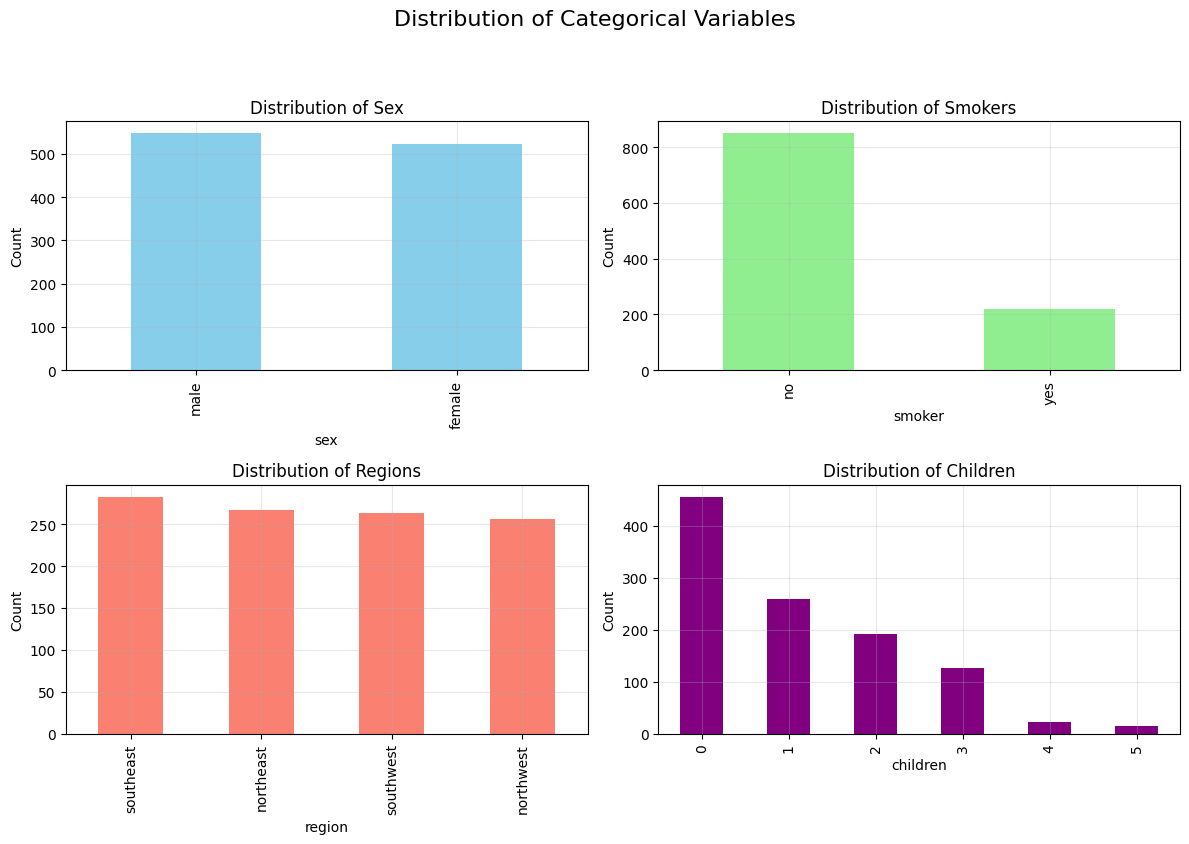

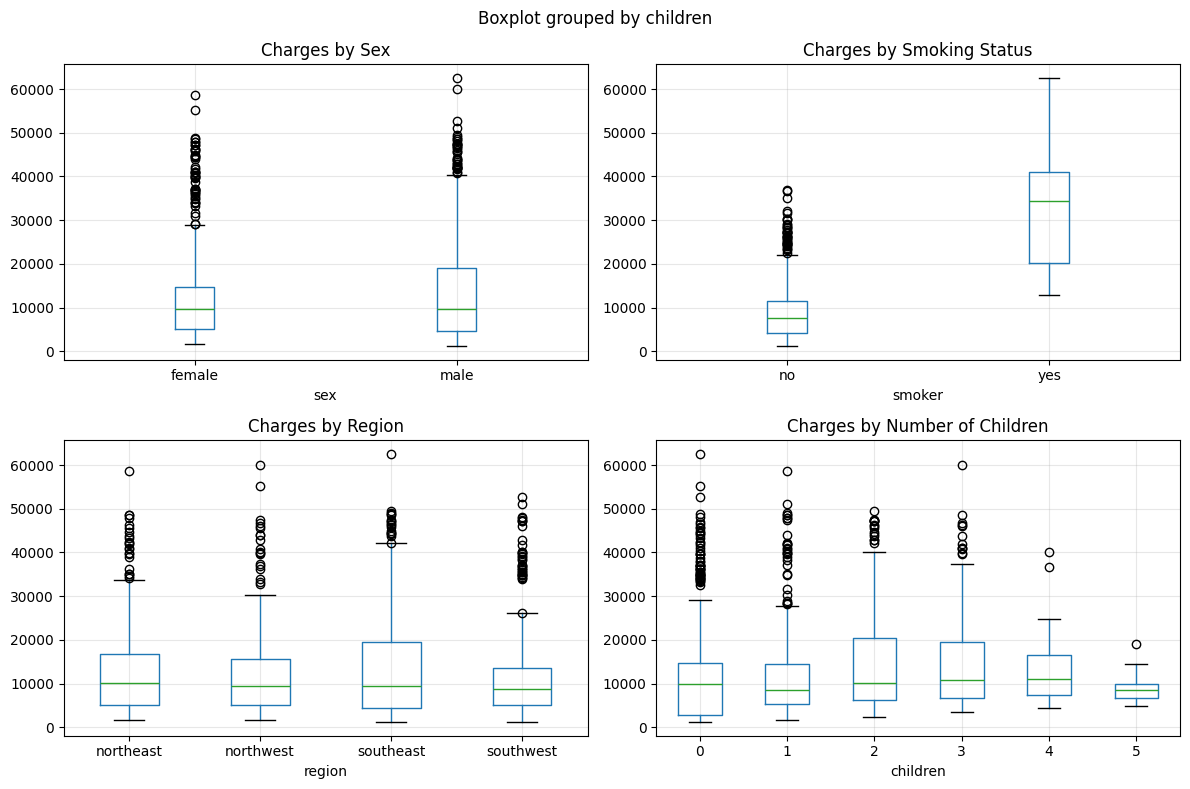


Summary Statistics by Categorical Variables:
--------------------------------------------------

Charges Statistics by SEX:


,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
female,522.0,12646.882679,10990.473003,1607.5101,5003.050275,9558.278000,14585.946738,58571.07448
male,548.0,14012.122736,12898.622647,1121.8739,4683.139575,9618.996575,18965.502690,62592.87309



Charges Statistics by SMOKER:


,count,mean,std,min,25%,50%,75%,max
smoker,,,,,,,,
no,850.0,8578.322548,6024.059796,1121.8739,4089.360887,7580.340950,11390.880512,36910.60803
yes,220.0,31767.008419,11636.198738,12829.4551,20162.832747,34278.610275,40934.643475,62592.87309



Charges Statistics by REGION:


,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
northeast,267.0,13333.008791,11186.425798,1694.79640,5070.464500,10141.13620,16717.01075,58571.07448
northwest,256.0,12622.514246,10998.851885,1625.43375,5123.036875,9408.24305,15569.43990,60021.39897
southeast,283.0,14698.242993,13727.062532,1121.87390,4407.444900,9504.31030,19518.75490,62592.87309
southwest,264.0,12611.500973,11759.691880,1241.56500,4986.566000,8824.18250,13453.97150,52590.82939



Charges Statistics by CHILDREN:


,count,mean,std,min,25%,50%,75%,max
children,,,,,,,,
0,456.0,12374.245032,11850.070099,1121.8739,2817.557563,9973.867725,14602.085437,62592.87309
1,259.0,12802.271121,11747.632341,1711.0268,5243.406000,8627.541100,14446.477700,58571.07448
2,191.0,15268.335673,12964.107407,2304.0022,6334.111350,10043.249000,20391.074075,49577.66240
3,127.0,15498.531251,12198.351853,3443.0640,6774.950625,10702.642400,19555.691090,60021.39897
4,22.0,13705.376080,9698.393378,4504.6624,7310.926950,11024.418200,16444.919098,40182.24600
5,15.0,9052.547130,3784.240551,4830.6300,6660.015800,8596.827800,9942.917950,19023.26000


In [ ]:
# we devide the train and test data before doing the EDA to avoid data leakage.
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)


# Set up the plotting parameters
plt.rcParams['figure.figsize'] = [12, 8] # اندازه نمودارها را بزرگ کردید تا جزئیات معلوم باشد
plt.rcParams['axes.grid'] = True # یک صفحه شطرنجی (Grid) پشت نمودار انداختید
plt.rcParams['grid.alpha'] = 0.3 # خطوط شطرنجی را کم‌رنگ کردید تا چشم را اذیت نکند

# Create subplots for categorical variables
fig, axes = plt.subplots(2, 2)
fig.suptitle('Distribution of Categorical Variables', fontsize=16, y=1.05)

# Plot distribution of sex
train_df['sex'].value_counts().plot(kind='bar', ax=axes[0,0], color='skyblue')
axes[0,0].set_title('Distribution of Sex')
axes[0,0].set_ylabel('Count')

# Plot distribution of smoker
train_df['smoker'].value_counts().plot(kind='bar', ax=axes[0,1], color='lightgreen')
axes[0,1].set_title('Distribution of Smokers')
axes[0,1].set_ylabel('Count')

# Plot distribution of region
train_df['region'].value_counts().plot(kind='bar', ax=axes[1,0], color='salmon')
axes[1,0].set_title('Distribution of Regions')
axes[1,0].set_ylabel('Count')

# Plot distribution of children
train_df['children'].value_counts().sort_index().plot(kind='bar', ax=axes[1,1], color='purple')
axes[1,1].set_title('Distribution of Children')
axes[1,1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Create box plots for charges by categorical variables
fig, axes = plt.subplots(2, 2)
fig.suptitle('Insurance Charges by Categorical Variables', fontsize=16, y=1.05)

# Box plot for sex
train_df.boxplot(column='charges', by='sex', ax=axes[0,0])
axes[0,0].set_title('Charges by Sex')

# Box plot for smoker
train_df.boxplot(column='charges', by='smoker', ax=axes[0,1])
axes[0,1].set_title('Charges by Smoking Status')

# Box plot for region
train_df.boxplot(column='charges', by='region', ax=axes[1,0])
axes[1,0].set_title('Charges by Region')

# Box plot for children
train_df.boxplot(column='charges', by='children', ax=axes[1,1])
axes[1,1].set_title('Charges by Number of Children')

plt.tight_layout()
plt.show()

# Calculate summary statistics for each categorical variable
print("\nSummary Statistics by Categorical Variables:")
print("-" * 50)
for col in categorical_cols:
    print(f"\nCharges Statistics by {col.upper()}:")
    display(train_df.groupby(col)['charges'].describe())


## Numerical Variables Analysis

We will analyze the following numerical variables:
- age (18-64 years)
- bmi (body mass index)
- charges (insurance charges)

For each numerical variable, we will:
1. Visualize their distribution
2. Identify potential outliers
3. Calculate summary statistics including skewness and kurtosis


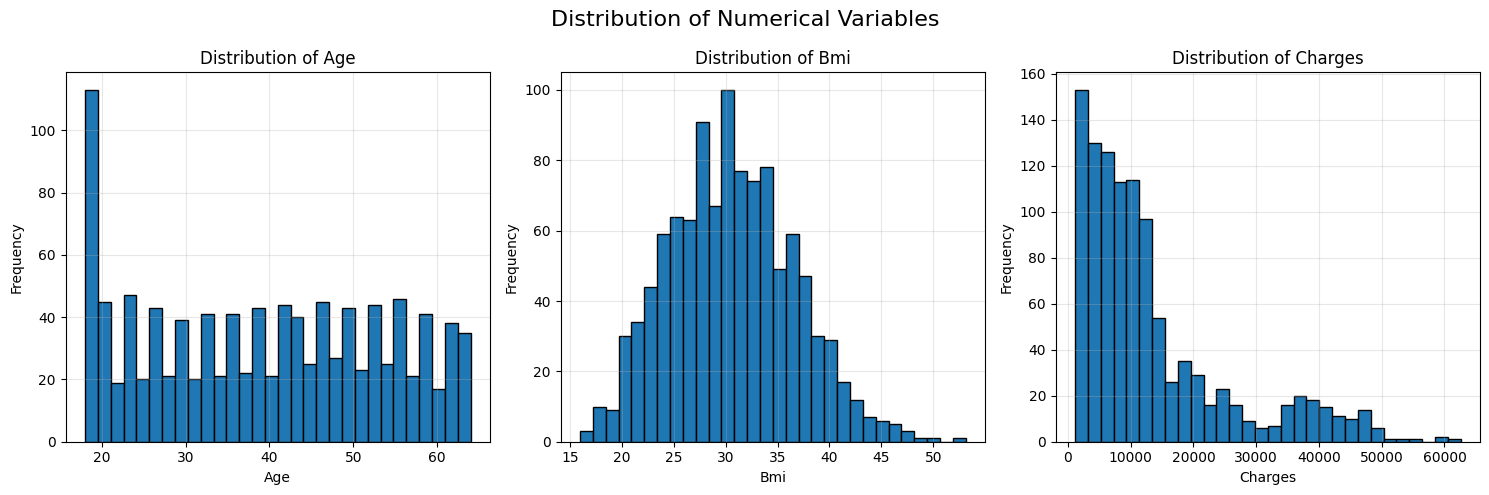

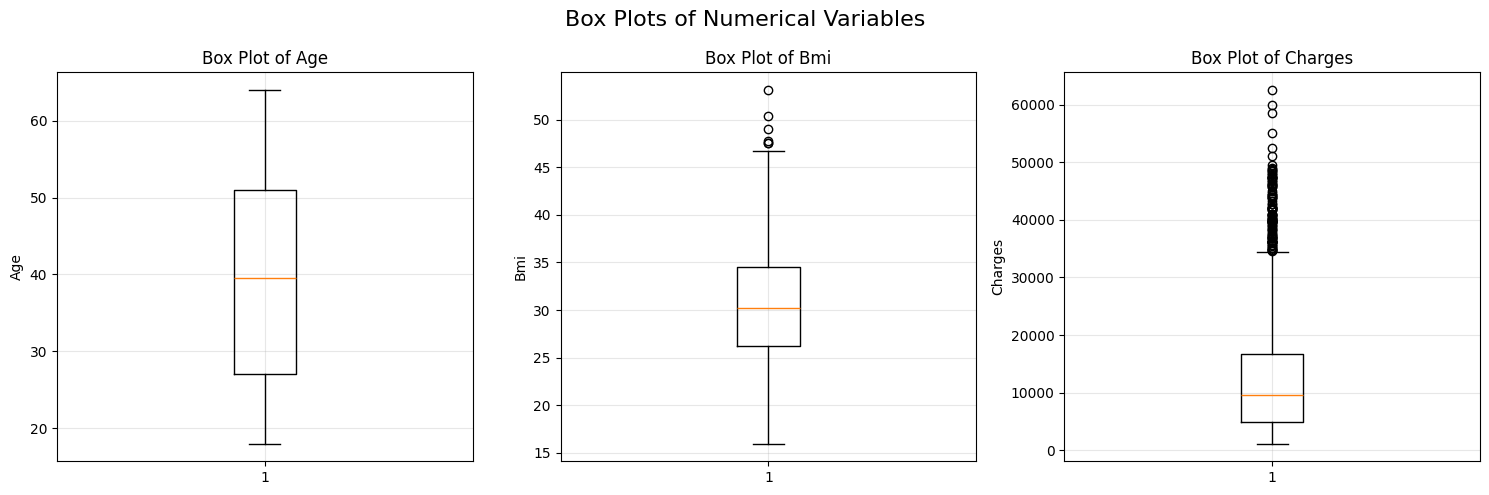


Detailed Statistics of Numerical Variables:
--------------------------------------------------


,min,max,mean,median,std,skewness
age,18.000,64.000,39.357,39.500,14.074,0.027
bmi,15.960,53.130,30.560,30.210,6.043,0.271
charges,1121.874,62592.873,13346.090,9575.442,12019.511,1.515


In [13]:
# Set up the numerical variables
numerical_cols = ['age', 'bmi', 'charges']

# Create histograms for numerical variables
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Distribution of Numerical Variables', fontsize=16)

for i, col in enumerate(numerical_cols):
    # Histogram
    axes[i].hist(train_df[col], bins=30, edgecolor='black')
    axes[i].set_title(f'Distribution of {col.title()}')
    axes[i].set_xlabel(col.title())
    axes[i].set_ylabel('Frequency')
    
plt.tight_layout()
plt.show()

# Create box plots for numerical variables
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Box Plots of Numerical Variables', fontsize=16)

for i, col in enumerate(numerical_cols):
    # Box plot
    axes[i].boxplot(train_df[col])
    axes[i].set_title(f'Box Plot of {col.title()}')
    axes[i].set_ylabel(col.title())
    
plt.tight_layout()
plt.show()

# Calculate summary statistics including skewness and kurtosis
print("\nDetailed Statistics of Numerical Variables:")
print("-" * 50)
stats_df = pd.DataFrame({
    'min': train_df[numerical_cols].min(),
    'max': train_df[numerical_cols].max(),
    'mean': train_df[numerical_cols].mean(),
    'median': train_df[numerical_cols].median(),
    'std': train_df[numerical_cols].std(),
    'skewness': train_df[numerical_cols].skew(),
    #'kurtosis': train_df[numerical_cols].kurtosis()
})
display(stats_df.round(3))


## Correlation Analysis

We will analyze the relationships between variables by:
1. Creating a correlation matrix with one-hot encoded categorical variables
2. Visualizing the correlation matrix
3. Creating scatter plots between numerical variables
4. Creating a pair plot for numerical variables


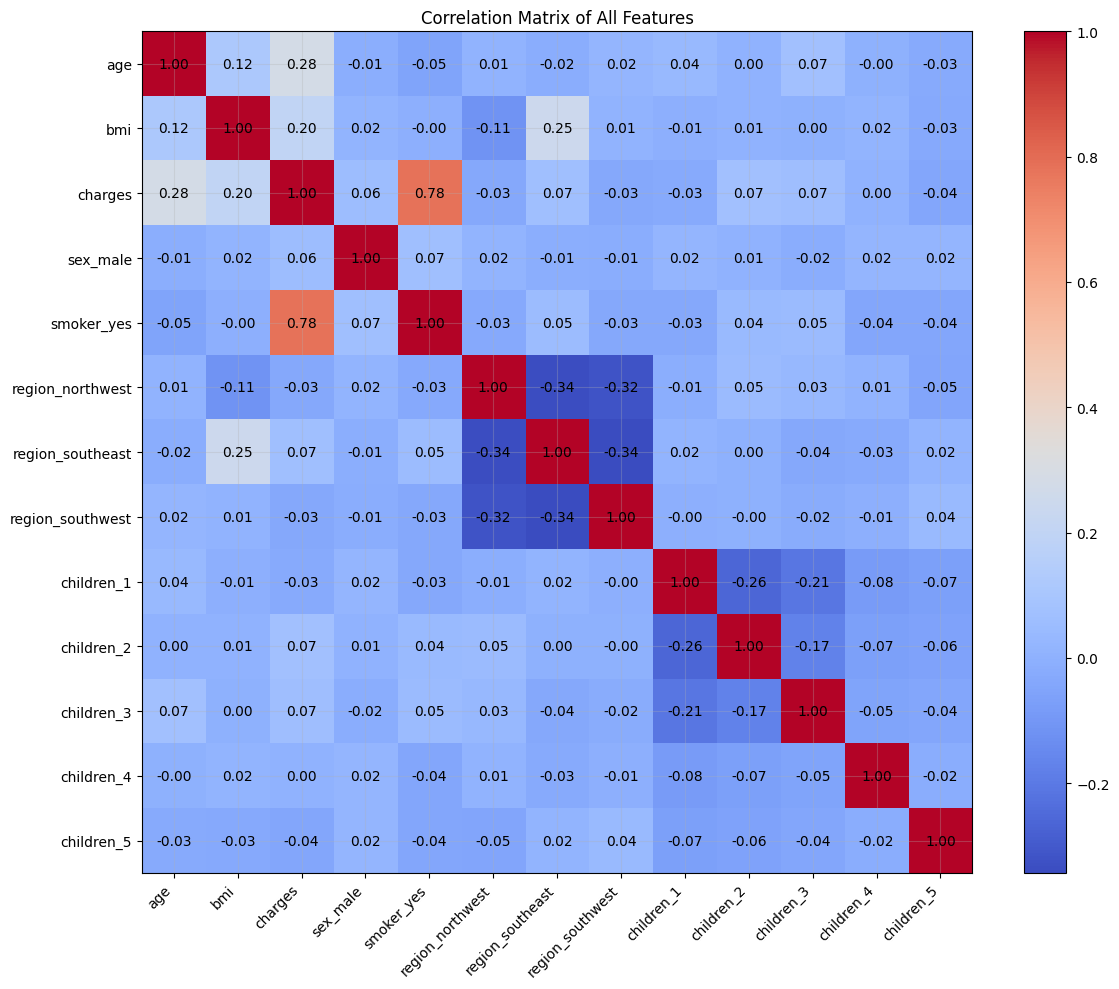

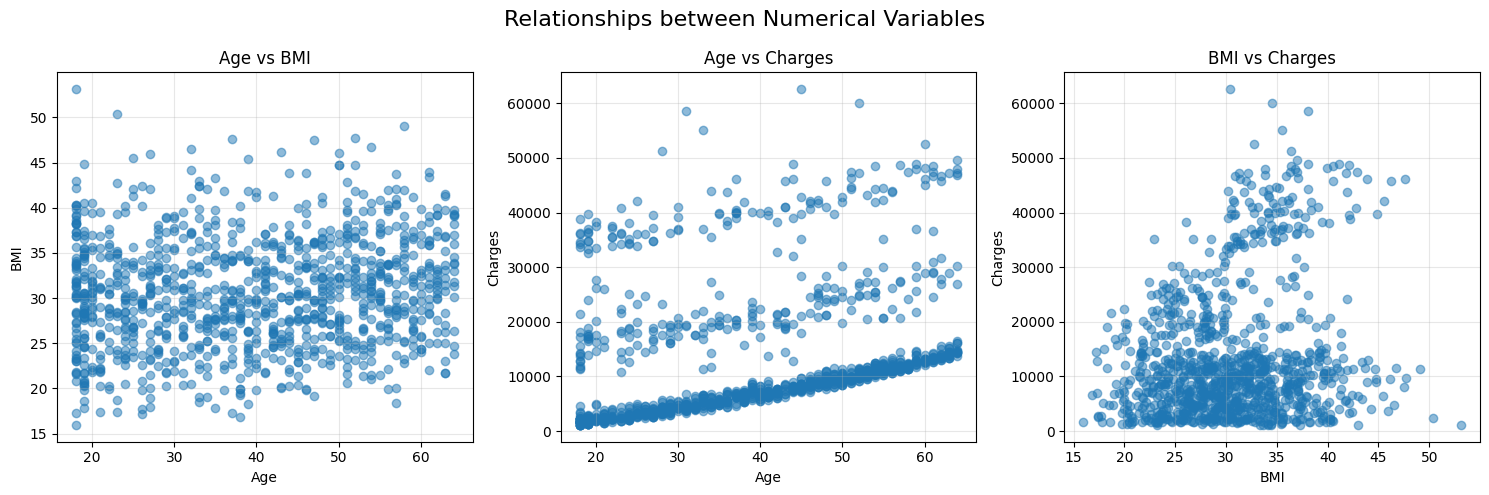

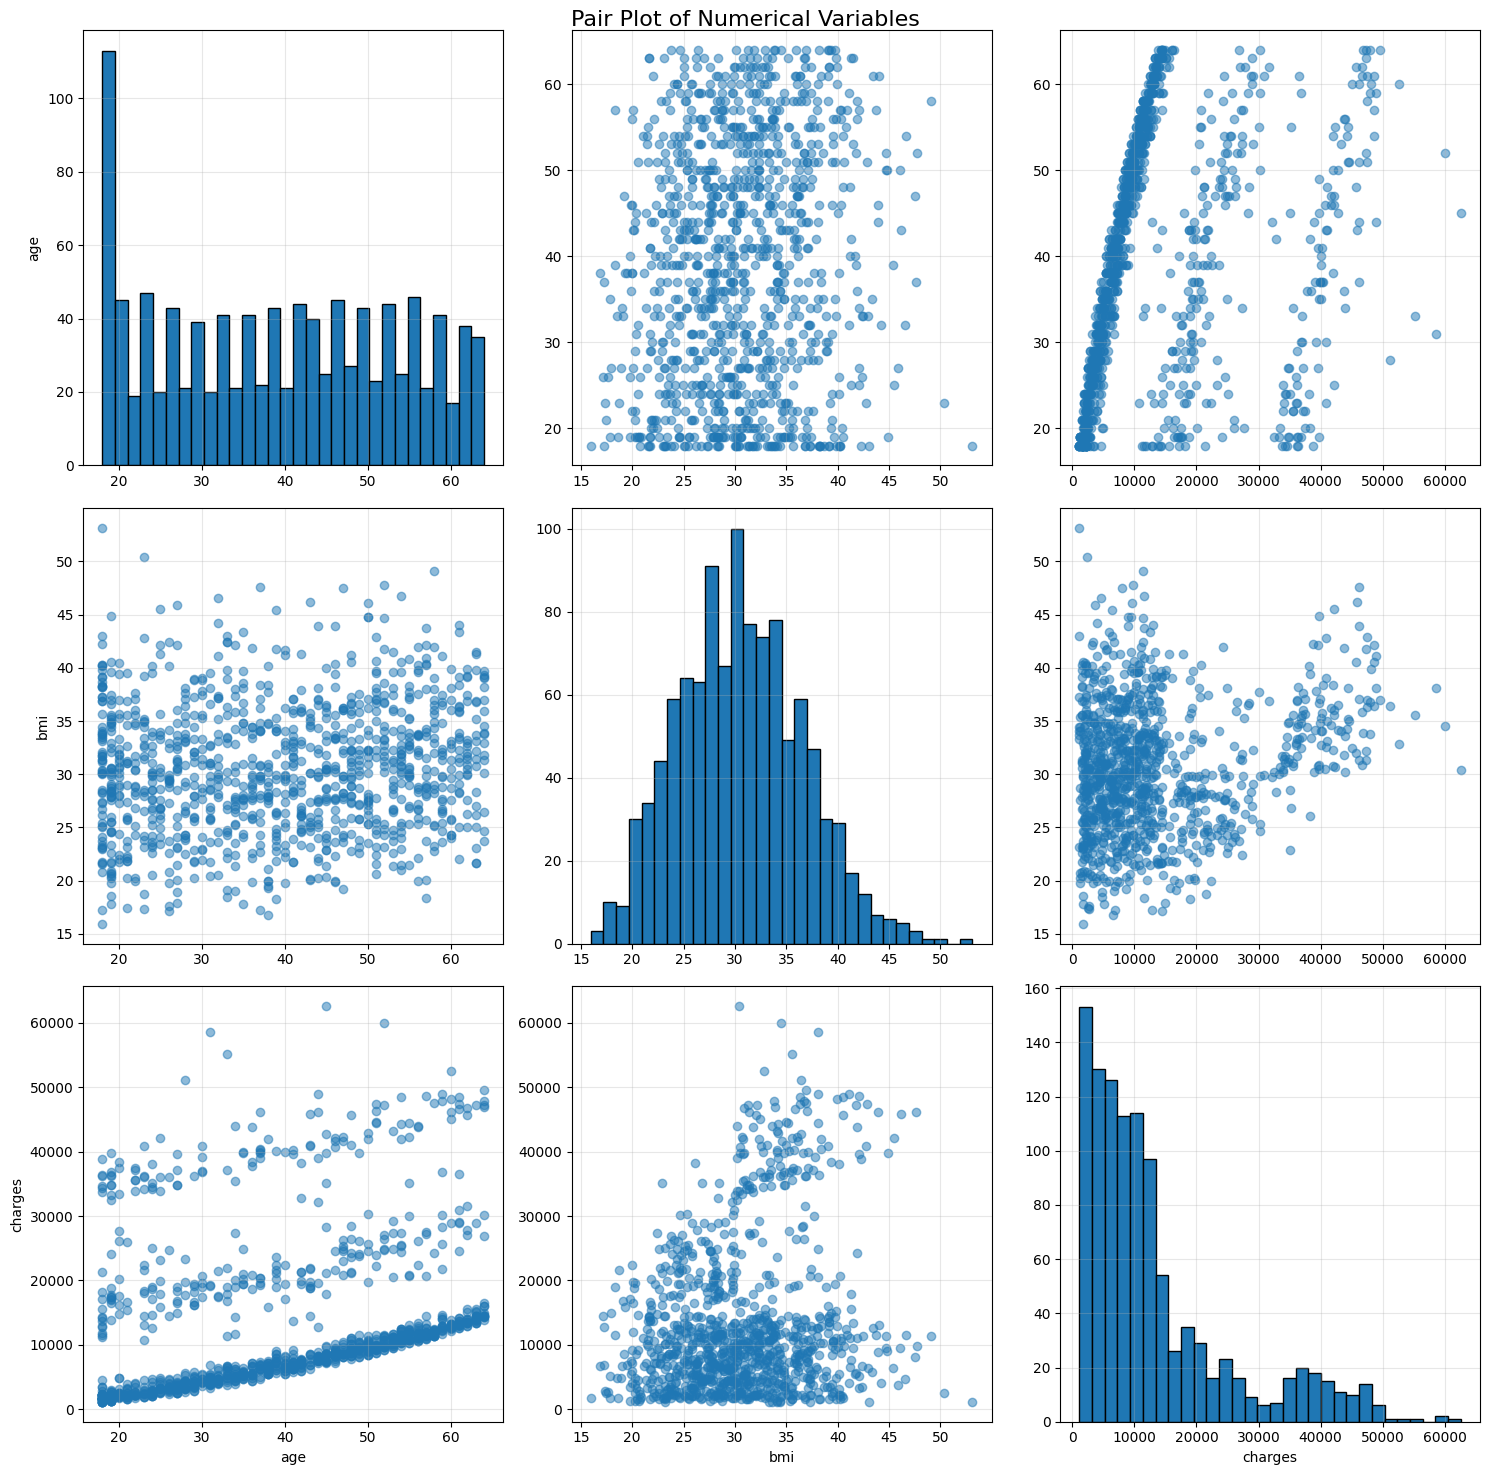

In [ ]:
# Create DataFrame for correlation analysis with one-hot encoding
df_encoded = pd.DataFrame()

# Add numerical variables
df_encoded['age'] = train_df['age']
df_encoded['bmi'] = train_df['bmi']
df_encoded['charges'] = train_df['charges']

# One-hot encode categorical variables (dropping one category for each to avoid multicollinearity)
sex_dummies = pd.get_dummies(train_df['sex'], prefix='sex', drop_first=True)
smoker_dummies = pd.get_dummies(train_df['smoker'], prefix='smoker', drop_first=True)
region_dummies = pd.get_dummies(train_df['region'], prefix='region', drop_first=True)
children_dummies = pd.get_dummies(train_df['children'], prefix='children', drop_first=True)

# Combine all features
df_encoded = pd.concat([
    df_encoded,
    sex_dummies,
    smoker_dummies,
    region_dummies,
    children_dummies
], axis=1)

# Calculate correlation matrix
correlation_matrix = df_encoded.corr()

# Create correlation heatmap
plt.figure(figsize=(12, 10))
plt.imshow(correlation_matrix, cmap='coolwarm', aspect='auto')
plt.colorbar()

# Add correlation values
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}",
                ha='center', va='center')

plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45, ha='right')
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.title('Correlation Matrix of All Features')
plt.tight_layout()
plt.show()

# Create scatter plots between numerical variables
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Relationships between Numerical Variables', fontsize=16)

# Age vs BMI
axes[0].scatter(train_df['age'], train_df['bmi'], alpha=0.5)
axes[0].set_xlabel('Age')
axes[0].set_ylabel('BMI')
axes[0].set_title('Age vs BMI')

# Age vs Charges
axes[1].scatter(train_df['age'], train_df['charges'], alpha=0.5)
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Charges')
axes[1].set_title('Age vs Charges')

# BMI vs Charges
axes[2].scatter(train_df['bmi'], train_df['charges'], alpha=0.5)
axes[2].set_xlabel('BMI')
axes[2].set_ylabel('Charges')
axes[2].set_title('BMI vs Charges')

plt.tight_layout()
plt.show()

# Create pair plot for numerical variables
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle('Pair Plot of Numerical Variables', fontsize=16)

for i, var1 in enumerate(numerical_cols):
    for j, var2 in enumerate(numerical_cols):
        if i == j:
            # Histogram on diagonal
            axes[i, j].hist(train_df[var1], bins=30, edgecolor='black')
        else:
            # Scatter plot on off-diagonal
            axes[i, j].scatter(train_df[var2], train_df[var1], alpha=0.5)
        
        if i == len(numerical_cols)-1:
            axes[i, j].set_xlabel(var2)
        if j == 0:
            axes[i, j].set_ylabel(var1)

plt.tight_layout()
plt.show()


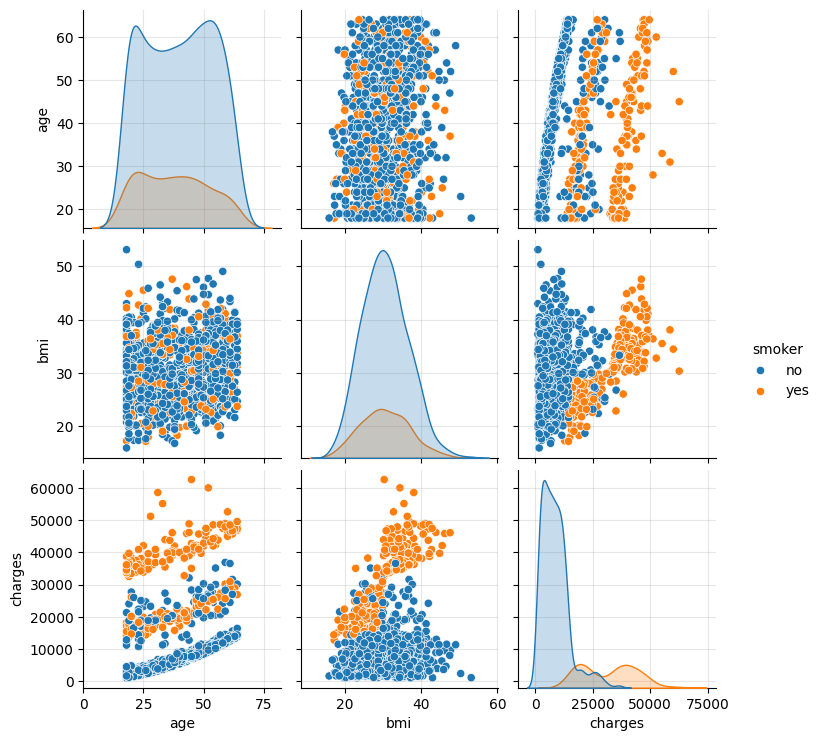

In [ ]:
import seaborn as sns
sns.pairplot(train_df, vars=['age', 'bmi', 'charges'], hue='smoker')
plt.show()

## Key Findings and Insights

1. **Data Quality**:
   - Dataset contains 1338 entries with 7 features
   - No missing values in any column
   - one duplicated row
   - All variables have appropriate data types

2. **Categorical Variables**:
   - Sex: Fairly balanced distribution between male and female
   - Smoker: Minority of smokers (~20-25%)
   - Region: Relatively even distribution across all four regions
   - Children: Most common are 0-2 children, fewer cases with 3+ children

3. **Numerical Variables**:
   - Age: 
     * Range: 18-64 years
     * Relatively uniform distribution
     * No significant outliers
   - BMI:
     * Range: ~15 to ~50
     * Approximately normal distribution
     * Some high-end outliers
   - Charges:
     * Strong right-skewed distribution
     * Significant number of outliers on the high end
     * Large variance in values

4. **Key Relationships**:
   - Strongest correlations with charges:
     * Smoking status (positive)
     * Age (positive)
     * BMI (positive)
   - Children and region show weaker correlations with charges
   - Age and BMI show weak correlation with each other

5. **Potential Modeling Considerations**:
   - Right-skewed distribution of charges might need transformation
   - Categorical variables properly encoded (avoiding dummy variable trap)
   - Presence of outliers in charges and BMI
   - Possible interaction effects between variables
   - Non-linear relationships between some variables

These insights will guide our data preparation and modeling strategies in the subsequent notebooks.
